<a href="https://colab.research.google.com/github/asmipandey18/Elevvo_Ml_Internship/blob/main/task9_predictive_maintenance/Predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 9: Industrial Predictive Maintenance

**Goal:** Predict machine failures from sensor readings, while keeping false alarms low. In a factory, a false alarm stops production for nothing, so the model is judged mainly by its False Discovery Rate (false alarms ÷ all alarms) and not by accuracy alone.

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (Kaggle, original upload by Matzka), 10,000 machine records with air temperature, process temperature, rotational speed, torque and tool wear.

**Tools:** Python, Pandas, Matplotlib, Seaborn, Scikit-learn, XGBoost

In [18]:
import pandas as pd

In [19]:
df = pd.read_csv("/content/ai4i2020.csv")

In [20]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [21]:
df.info()
print(df.columns.tolist())
print(df["Machine failure"].value_counts())
print(df["Machine failure"].value_counts(normalize=True).round(4))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

### Observation: Data Overview

The dataset has 10,000 rows and 14 columns with no missing values. Only 339 rows (3.39%) are failures, so the data is severely imbalanced: a model that always predicted “no failure” would reach 96.6% accuracy while detecting nothing. Accuracy is therefore not a useful metric, and I will focus on precision, False Discovery Rate and recall. The columns TWF, HDF, PWF, OSF and RNF describe the failure type and directly determine Machine failure, so they will not be used as features.

## Data cleaning and preparation

In [22]:
# Rename columns (XGBoost does not accept [ ] in names)
df = df.rename(columns={
    "Air temperature [K]": "Air_temp",
    "Process temperature [K]": "Process_temp",
    "Rotational speed [rpm]": "Rot_speed",
    "Torque [Nm]": "Torque",
    "Tool wear [min]": "Tool_wear",
    "Machine failure": "Machine_failure",
})

# Drop ID columns (they only identify rows)
df = df.drop(columns=["UDI", "Product ID"])

# Encode product quality: L < M < H
df["Type"] = df["Type"].map({"L": 0, "M": 1, "H": 2})

# Check that Machine_failure matches the failure-type columns
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mismatch = df[(df["Machine_failure"] == 1) & (df[failure_cols].sum(axis=1) == 0)]
print("Failures with no failure type flagged:", len(mismatch))
print(df.isnull().sum().sum(), "missing values |", df.duplicated().sum(), "duplicate rows")
df.head()

Failures with no failure type flagged: 9
0 missing values | 0 duplicate rows


,Type,Air_temp,Process_temp,Rot_speed,Torque,Tool_wear,Machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,0,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,0,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,0,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,0,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Observation: Data Cleaning

The dataset has no missing values and no duplicate rows. The ID columns (UDI, Product ID) were dropped because they only identify rows, the column names were simplified (XGBoost does not accept brackets in names), and the product quality Type was encoded as 0, 1 and 2 (Low, Medium, High). The failure-type columns (TWF, HDF, PWF, OSF, RNF) will not be used as features because they define Machine_failure directly. Nine failure rows have no failure type flagged, which contradicts the dataset description, but I kept them because they are labeled failures and are only 9 of 339.

## Exploratory Data Analysis(EDA)

### Class Imbalance and Failure Types

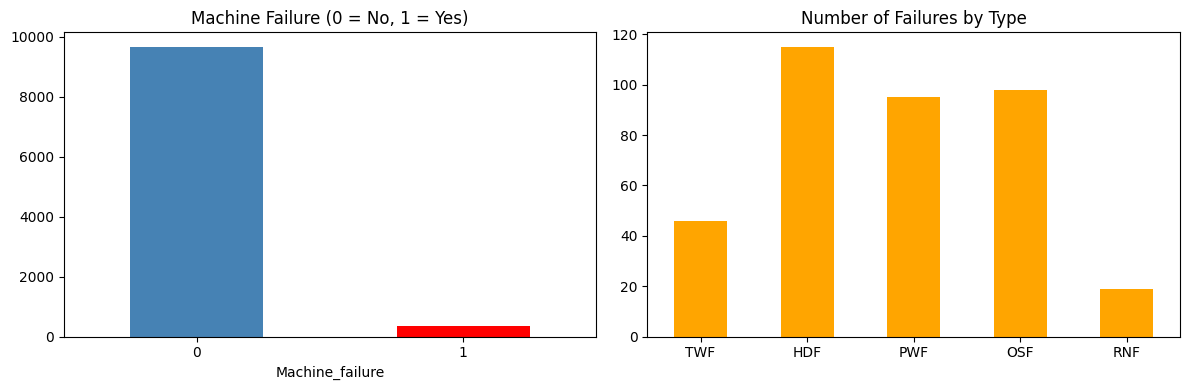

TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns


fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Machine_failure"].value_counts().plot(kind="bar", ax=ax[0], color=["steelblue", "red"])
ax[0].set_title("Machine Failure (0 = No, 1 = Yes)")
ax[0].tick_params(axis="x", rotation=0)
df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum().plot(kind="bar", ax=ax[1], color="orange")
ax[1].set_title("Number of Failures by Type")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()
print(df[["TWF", "HDF", "PWF", "OSF", "RNF"]].sum())

### Observation: Class Imbalance and Failure Types

Only 339 of 10,000 rows (3.4%) are failures, so the data is severely imbalanced. The most common failure types are heat dissipation (HDF, 115), overstrain (OSF, 98) and power failure (PWF, 95), followed by tool wear (TWF, 46) and random failures (RNF, 19). The type counts add up to more than 339, so some rows have more than one failure mode. Random failures happen regardless of the sensor readings, so no model can predict them, and this limits how many failures can be caught.

### Sensor Readings: Normal vs Failure

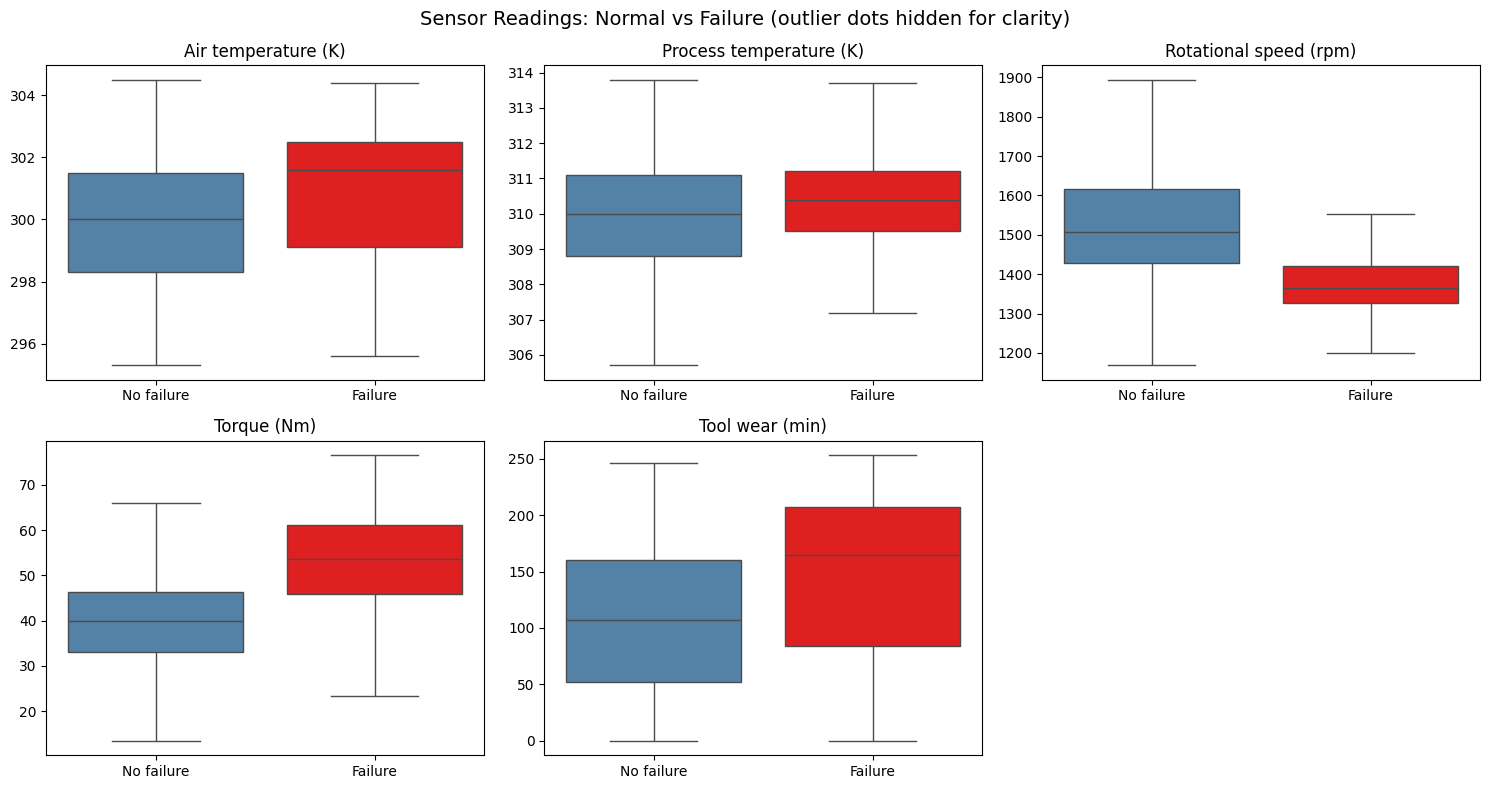

In [24]:
sensors = ["Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear"]
titles = {"Air_temp": "Air temperature (K)", "Process_temp": "Process temperature (K)",
          "Rot_speed": "Rotational speed (rpm)", "Torque": "Torque (Nm)", "Tool_wear": "Tool wear (min)"}

plot_df = df.copy()
plot_df["Status"] = plot_df["Machine_failure"].map({0: "No failure", 1: "Failure"})

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for a, col in zip(ax, sensors):
    sns.boxplot(x="Status", y=col, hue="Status", data=plot_df, ax=a,
                order=["No failure", "Failure"], hue_order=["No failure", "Failure"],
                palette=["steelblue", "red"], showfliers=False, legend=False)
    a.set_xlabel("")
    a.set_ylabel("")
    a.set_title(titles[col])
ax[5].axis("off")
plt.suptitle("Sensor Readings: Normal vs Failure (outlier dots hidden for clarity)", fontsize=14)
plt.tight_layout()
plt.show()

### Observation: Sensor Readings

Torque and rotational speed show the clearest difference between normal and failed machines: failures have much higher torque (median about 53 Nm vs about 40 Nm) and lower rotational speed (about 1,370 vs about 1,500 rpm). Failed machines also tend to have more tool wear, but the boxes overlap a lot. Air and process temperature differ only slightly between the two groups. No single sensor separates failures cleanly, so combinations of sensors (such as power = torque × speed, and the temperature difference) should help the model. Outlier dots were hidden to make the boxes easier to compare.

### Failure Rate by Product Type

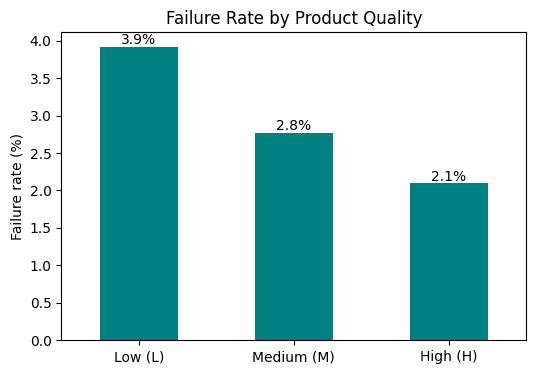

In [25]:
rate = df.groupby("Type")["Machine_failure"].mean() * 100
ax = rate.plot(kind="bar", color="teal", figsize=(6, 4))
ax.set_xticklabels(["Low (L)", "Medium (M)", "High (H)"], rotation=0)
for i, v in enumerate(rate.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.title("Failure Rate by Product Quality")
plt.ylabel("Failure rate (%)")
plt.xlabel("")
plt.show()

### Observation: Failure Rate by Product Quality

Failure rate falls as product quality rises: 3.9% for Low, 2.8% for Medium and 2.1% for High quality products, so low-quality products fail almost twice as often as high-quality ones. This suggests that Type is a useful feature, though the differences are modest compared with the effect of torque and rotational speed.

### Correlation Heatmap

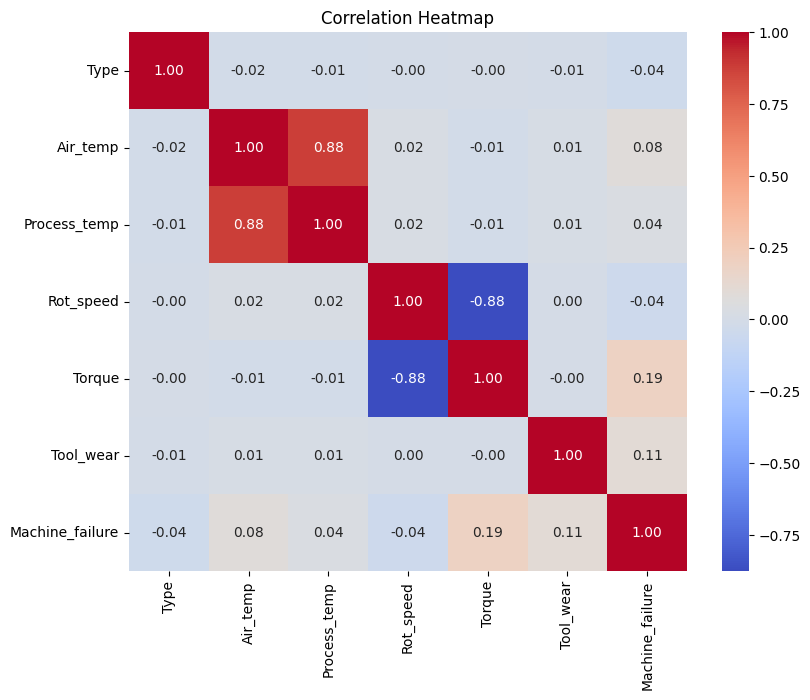

In [26]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF"]).corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### Observation: Correlation Analysis

Torque has the strongest correlation with machine failure (0.19), followed by tool wear (0.11) and air temperature (0.08), so torque is the lead indicator among the individual sensors. All correlations are weak, which means failures are driven by combinations of sensors and not by any single reading. Air and process temperature are strongly correlated with each other (0.88), and rotational speed and torque are strongly negatively correlated (-0.88), so these pairs carry overlapping information. This motivates feature engineering, such as the temperature difference and power (torque × rotational speed).

## Feature Engineering

In [27]:
import numpy as np

df_fe = df.copy()

# Temperature difference (heat dissipation depends on the gap and on speed)
df_fe["Temp_diff"] = df_fe["Process_temp"] - df_fe["Air_temp"]

# Power in watts = torque (Nm) x rotational speed converted to rad/s
df_fe["Power"] = df_fe["Torque"] * df_fe["Rot_speed"] * 2 * np.pi / 60

# Overstrain: tool wear x torque
df_fe["Wear_x_Torque"] = df_fe["Tool_wear"] * df_fe["Torque"]

df_fe[["Temp_diff", "Power", "Wear_x_Torque", "Machine_failure"]].corr().round(2)

,Temp_diff,Power,Wear_x_Torque,Machine_failure
Temp_diff,1.00,0.01,-0.01,-0.11
Power,0.01,1.00,0.37,0.18
Wear_x_Torque,-0.01,0.37,1.00,0.19
Machine_failure,-0.11,0.18,0.19,1.00


### Observation: Feature Engineering

I created three features from the physics of the machine: the temperature difference (process − air), the mechanical power (torque × rotational speed in rad/s), and tool wear × torque. Temp_diff correlates more strongly with failure (-0.11) than either temperature alone, and Power (0.18) and Wear × Torque (0.19) are much stronger than rotational speed alone (-0.04). The correlations are still modest because failures follow threshold rules (for example power outside a safe range), which tree-based models can capture better than a linear relationship.

## Train-Test Split

In [28]:
from sklearn.model_selection import train_test_split

features = ["Type", "Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear",
            "Temp_diff", "Power", "Wear_x_Torque"]

X = df_fe[features]
y = df_fe["Machine_failure"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Failures in train:", y_train.sum(), "| in test:", y_test.sum())
print("Failure rate train: %.2f%% | test: %.2f%%" % (y_train.mean() * 100, y_test.mean() * 100))

Train: (8000, 9) | Test: (2000, 9)
Failures in train: 271 | in test: 68
Failure rate train: 3.39% | test: 3.40%


### Observation: Train-Test Split

The data was split 80/20 with stratification into 8,000 training rows (271 failures) and 2,000 test rows (68 failures), keeping the failure rate at about 3.4% in both. The failure-type columns (TWF, HDF, PWF, OSF, RNF) were excluded from the features to avoid data leakage. Because the test set contains only 68 failures, metrics such as the False Discovery Rate can change noticeably with just a few predictions.

## Baseline Models

In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

def report(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    fdr = fp / (fp + tp) if (fp + tp) > 0 else 0
    return {"Model": name, "Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred),
            "False Alarms (FP)": fp, "Missed Failures (FN)": fn, "FDR": fdr}

# Dummy baseline: always predict "no failure"
dummy_pred = np.zeros(len(y_test), dtype=int)

rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

baseline = pd.DataFrame([report("Always 'no failure'", y_test, dummy_pred),
                         report("Random Forest (default)", y_test, rf_pred)]).round(3)
baseline

,Model,Accuracy,Precision,Recall,F1,False Alarms (FP),Missed Failures (FN),FDR
0,Always 'no failure',0.966,0.000,0.000,0.000,0,68,0.000
1,Random Forest (default),0.993,0.966,0.824,0.889,2,12,0.034


### Observation: Baseline Models

A model that always predicts “no failure” reaches 96.6% accuracy but misses all 68 failures, so accuracy is misleading here. A default Random Forest reaches 99.3% accuracy with only 2 false alarms and 12 missed failures (precision 0.966, recall 0.824, False Discovery Rate 0.034). Since the test set has only 68 failures, small differences in false alarms are not very reliable.

## Threshold Tuning for a Low False Discovery Rate

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from xgboost import XGBClassifier

TARGET_FDR = 0.02          # change this to the false-alarm level you want
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
yt = y_train.values
pos_weight = (yt == 0).sum() / (yt == 1).sum()

def tune_and_eval(name, model):
    # 1) out-of-fold probabilities on the TRAINING set
    oof = cross_val_predict(model, X_train, yt, cv=skf, method="predict_proba")[:, 1]
    best_t, best_rec = 0.5, -1
    for t in np.arange(0.05, 0.96, 0.01):
        pred = (oof >= t).astype(int)
        tp = ((pred == 1) & (yt == 1)).sum()
        fp = ((pred == 1) & (yt == 0)).sum()
        if tp + fp == 0:
            continue
        fdr, rec = fp / (tp + fp), tp / (yt == 1).sum()
        if fdr <= TARGET_FDR and rec > best_rec:
            best_t, best_rec = t, rec
    # 2) fit on all training data, apply the chosen threshold ONCE on the test set
    model.fit(X_train, yt)
    proba = model.predict_proba(X_test)[:, 1]
    return report(f"{name} (threshold {best_t:.2f})", y_test, (proba >= best_t).astype(int))

rows = [
    tune_and_eval("Random Forest", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
    tune_and_eval("Random Forest (balanced)", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1)),
    tune_and_eval("XGBoost", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, eval_metric="logloss", random_state=42)),
    tune_and_eval("XGBoost (weighted)", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42)),
]
tuned = pd.DataFrame(rows).round(3)
tuned

,Model,Accuracy,Precision,Recall,F1,False Alarms (FP),Missed Failures (FN),FDR
0,Random Forest (threshold 0.53),0.992,0.965,0.809,0.880,2,13,0.035
1,Random Forest (balanced) (threshold 0.53),0.990,0.962,0.735,0.833,2,18,0.038
2,XGBoost (threshold 0.50),0.991,0.931,0.794,0.857,4,14,0.069
3,XGBoost (weighted) (threshold 0.50),0.984,0.740,0.838,0.786,20,11,0.260


### Observation: Threshold Tuning and Cost-Sensitive Models

Random Forest gave the lowest False Discovery Rate (0.035, with 2 false alarms) while still catching 55 of 68 failures. Tuning the threshold barely changed it compared with the default model (2 false alarms, 12 missed), because with only 68 test failures one prediction is within noise. Cost-sensitive weighting that favours failures raised recall for XGBoost (0.838) but caused 20 false alarms (FDR 0.26), which conflicts with the goal of avoiding costly false alarms. Because the priority is to keep false alarms low, I chose the Random Forest with threshold 0.53.

### False Discovery Rate vs Recall

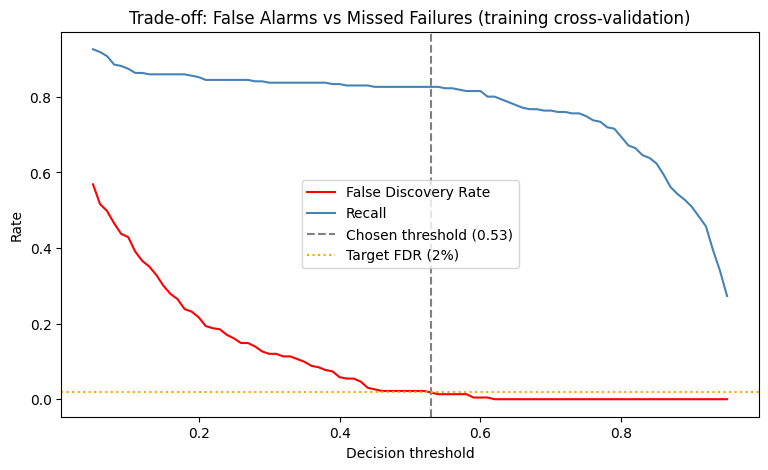

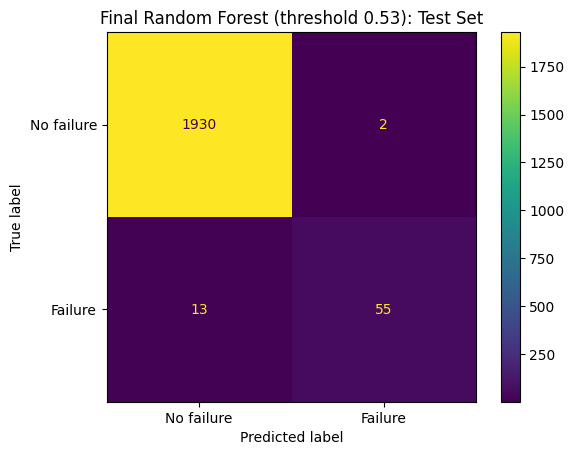

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

rf_final = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
oof = cross_val_predict(rf_final, X_train, yt, cv=skf, method="predict_proba")[:, 1]

ths = np.arange(0.05, 0.96, 0.01)
fdrs, recs = [], []
for t in ths:
    pred = (oof >= t).astype(int)
    tp = ((pred == 1) & (yt == 1)).sum()
    fp = ((pred == 1) & (yt == 0)).sum()
    fdrs.append(fp / (tp + fp) if tp + fp > 0 else np.nan)
    recs.append(tp / (yt == 1).sum())

plt.figure(figsize=(9, 5))
plt.plot(ths, fdrs, color="red", label="False Discovery Rate")
plt.plot(ths, recs, color="steelblue", label="Recall")
plt.axvline(0.53, linestyle="--", color="gray", label="Chosen threshold (0.53)")
plt.axhline(TARGET_FDR, linestyle=":", color="orange", label="Target FDR (2%)")
plt.xlabel("Decision threshold")
plt.ylabel("Rate")
plt.title("Trade-off: False Alarms vs Missed Failures (training cross-validation)")
plt.legend()
plt.show()

# Final model: confusion matrix on the test set
rf_final.fit(X_train, yt)
final_pred = (rf_final.predict_proba(X_test)[:, 1] >= 0.53).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=["No failure", "Failure"])
plt.title("Final Random Forest (threshold 0.53): Test Set")
plt.show()

### Observation: False Discovery Rate vs Recall

As the decision threshold rises, the False Discovery Rate falls quickly and approaches zero by a threshold of about 0.45 to 0.5, while recall stays roughly constant (about 0.83) up to a threshold of about 0.6 and only drops sharply beyond about 0.65. A threshold of 0.53 therefore removes almost all false alarms without losing many true detections. On the test set, the final Random Forest produced only 2 false alarms and caught 55 of 68 failures, with 13 missed. These counts are small, so they are only a rough guide.

## Predicting the Failure Type

In [32]:
types = {"TWF": "Tool Wear", "HDF": "Heat Dissipation", "PWF": "Power", "OSF": "Overstrain"}

rows = []
for col, name in types.items():
    ytr = df_fe.loc[X_train.index, col]
    yte = df_fe.loc[X_test.index, col]
    m = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
    m.fit(X_train, ytr)
    pred = m.predict(X_test)
    r = report(name, yte, pred)
    r["Failures in test"] = int(yte.sum())
    rows.append(r)

pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,False Alarms (FP),Missed Failures (FN),FDR,Failures in test
0,Tool Wear,0.995,0.000,0.000,0.000,0,10,0.000,10
1,Heat Dissipation,0.998,0.931,0.931,0.931,2,2,0.069,29
2,Power,1.000,1.000,1.000,1.000,0,0,0.000,13
3,Overstrain,1.000,1.000,1.000,1.000,0,0,0.000,16


### Observation: Predicting the Failure Type

One Random Forest was trained per failure type, using the same features and split. Power and Overstrain failures were predicted perfectly on the test set (no false alarms, no misses), which is consistent with the engineered features Power (torque × speed) and Wear × Torque capturing their underlying rules. Heat Dissipation was predicted well (27 of 29 caught, 2 false alarms, FDR 0.069). Tool Wear could not be detected at all: the model raised no alarms and missed all 10 failures, which is likely because tool-wear failures occur at a random wear value between 200 and 240 minutes and are not clearly separable from sensor readings. Each type has only 10 to 29 failures in the test set, so these results are unstable.

### Tool Wear: Lower Thresholds and Class Weights

In [33]:
ytr = df_fe.loc[X_train.index, "TWF"]
yte = df_fe.loc[X_test.index, "TWF"]
m = RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", random_state=42, n_jobs=-1)
m.fit(X_train, ytr)
proba = m.predict_proba(X_test)[:, 1]

rows = [report(f"Tool Wear (threshold {t})", yte, (proba >= t).astype(int)) for t in [0.1, 0.2, 0.3, 0.5]]
pd.DataFrame(rows).round(3)

,Model,Accuracy,Precision,Recall,F1,False Alarms (FP),Missed Failures (FN),FDR
0,Tool Wear (threshold 0.1),0.979,0.079,0.3,0.125,35,7,0.921
1,Tool Wear (threshold 0.2),0.992,0.000,0.0,0.000,7,10,1.000
2,Tool Wear (threshold 0.3),0.995,0.000,0.0,0.000,0,10,0.000
3,Tool Wear (threshold 0.5),0.995,0.000,0.0,0.000,0,10,0.000


### Observation: Tool Wear

Class weighting and lower thresholds did not make Tool Wear failures reliably detectable. At a threshold of 0.1 the model caught 3 of 10 failures but raised 35 false alarms (FDR 0.92), and at higher thresholds it caught none. Since false alarms are the main cost in this task, I do not recommend using a model for this failure type. This is likely because tool-wear failures occur at a randomly selected wear value between 200 and 240 minutes, so the sensor readings do not clearly separate them. A practical alternative is a simple rule: schedule a tool change when tool wear approaches 200 minutes.

## Anomaly Detection (Isolation Forest)

In [34]:
from sklearn.ensemble import IsolationForest

# Unsupervised: the model never sees the failure labels while training
iso = IsolationForest(n_estimators=300, contamination=float(y_train.mean()), random_state=42)
iso.fit(X_train)
iso_pred = (iso.predict(X_test) == -1).astype(int)    # -1 means "anomaly"

compare = pd.DataFrame([
    report("Isolation Forest (unsupervised)", y_test, iso_pred),
    report("Random Forest (supervised, tuned)", y_test, final_pred),
]).round(3)
compare

,Model,Accuracy,Precision,Recall,F1,False Alarms (FP),Missed Failures (FN),FDR
0,Isolation Forest (unsupervised),0.952,0.271,0.235,0.252,43,52,0.729
1,"Random Forest (supervised, tuned)",0.992,0.965,0.809,0.880,2,13,0.035


### Observation: Anomaly Detection

An unsupervised Isolation Forest, trained without failure labels, performed much worse than the supervised Random Forest: it raised 43 false alarms (False Discovery Rate 0.73) and caught only 16 of 68 failures, compared with 2 false alarms (FDR 0.035) and 55 caught for the Random Forest. Many failures are not unusual on any single sensor, so unlabeled anomaly detection is not suitable for keeping false alarms low here, and the labeled supervised model is the better choice.

## Conclusion
The goal was to predict machine failures from sensor readings while keeping false alarms low, because a false alarm stops production for no reason. Only 3.4% of the 10,000 records are failures, so accuracy is misleading: a model that always predicts "no failure" scores 96.6% while detecting nothing. I evaluated models with the False Discovery Rate (FDR = false alarms ÷ all alarms), alongside recall.

**Results:**
- A tuned Random Forest was the best model: 2 false alarms (FDR 0.035) and 55 of 68 failures caught. Threshold tuning changed little compared with the default model.
- Cost-sensitive weighting for XGBoost raised recall but caused 20 false alarms (FDR 0.26), which conflicts with the goal.
- Engineered features (temperature difference, power = torque × speed, and wear × torque) were more informative than the raw sensors. Torque was the strongest single sensor (correlation 0.19).
- Per failure type, Power and Overstrain were predicted perfectly and Heat Dissipation well (FDR 0.069), but Tool Wear could not be detected without many false alarms (FDR 0.92 at best), probably because tool-wear failures occur at a randomly chosen wear value.
- An unsupervised Isolation Forest was far worse (FDR 0.73) than the supervised model.

**Limitations:** the test set has only 68 failures (10 to 29 per type), so the results are unstable, and the 2% FDR target was not reached on the test set (0.035). The dataset has no timestamps, so a time-to-failure model was not possible. The data is synthetic.

**Future work:** use repeated cross-validation for more reliable estimates, handle Tool Wear with a simple rule (change the tool near 200 minutes of wear), and test on real machine data.
